# 🐢 06 · Naive Training of Word2Vec (Full Softmax)

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 6 of 9
> Course notes: pages 13–14 – $\Delta u_k=\eta(\delta_{ok}-y_k)h^\top$, $\Delta v=\eta(u_o-\sum_iy_iu_i)$, *"All d×n update ≈ 3×10⁷ … roughly 10⁷ updates – too expensive"*, *"Where are my vectors? Each column of V"*

Notebook 05 derived the gradients for **one** training pair. Now we apply them to **all 31 734 pairs** of our corpus, many times over, with stochastic gradient descent (SGD). This is the original, "naive" word2vec: every step computes the full softmax over the whole vocabulary.

We will see two things:
1. **It works.** The columns of $V$ become word vectors where similar words are close and *king − man + woman ≈ queen*.
2. **It is slow.** Each step touches all $n\times d$ numbers of $U$. With a real vocabulary that is the $\approx3\times10^7$ updates per step from the notes – the reason notebooks 07 and 08 exist.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | The SGD training loop for skip-gram, split into small pieces |
| 2 | Reading the loss: the starting value $\log n$ and the best possible value (the true conditional entropy) |
| 3 | What the trained network predicts, and what its weight matrix $V$ has learned |
| 4 | Nearest neighbours, a 2-D map and analogies with the learned vectors |
| 5 | Measuring the cost of one step as $n$ grows |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
import time

---
## 1 · The variables

### 📖 Notation for the word2vec notebooks (same as the course notes, pages 10–14)

| Symbol | Shape | Meaning |
|---|---|---|
| $n$ | number | vocabulary size: how many different words we know |
| $d$ | number | embedding size: how many numbers describe one word (notes: typically 300) |
| $w_k$ | – | the $k$-th word of the vocabulary, $k=1..n$ |
| $x$ | $n\times1$ | one-hot vector of the **input** word: all zeros except a 1 at its index |
| $V$ | $d\times n$ | **input** matrix. Column $k$, written $v_k$, is the **word vector** of $w_k$ |
| $h=Vx$ | $d\times1$ | hidden vector. Because $x$ is one-hot, $h$ is simply the column $v_c$ of the input word $c$ |
| $U$ | $n\times d$ | **output** matrix. Row $k$, written $u_k$, is the "output vector" of $w_k$ |
| $z=Uh$ | $n\times1$ | one score per vocabulary word: $z_k=u_k\cdot h$ |
| $y=\text{softmax}(z)$ | $n\times1$ | probabilities: $y_k=e^{z_k}/\sum_{m}e^{z_m}$ = predicted chance that $w_k$ is the context word |
| $o$ | index | the **true** output (context) word of this training example |
| $E=-\log y_o$ | number | error: minus the log of the probability given to the right word |
| $\delta_{ok}$ | number | Kronecker delta: 1 if $o=k$, else 0 |
| $\eta$ | number | learning rate |

No biases and no activation function except the final softmax, so the model has exactly $2\ d\ n$ parameters (notes, page 10).
New in this notebook:

| Symbol | Meaning |
|---|---|
| $N$ | number of training pairs $(c,o)$ in the corpus |
| epoch | one pass over all $N$ pairs, in random order |
| $\bar E$ | average error over many pairs: $\bar E=\frac1N\sum E$ |

---
## 2 · The data 📚

Same corpus as notebooks 02–04: sentences about 8 people (with hidden attributes *royal/common, male/female, adult/young*) and about 4 kinds of things.

In [2]:
PEOPLE = {   # word: (status, gender, age)
    "king": ("royal", "male", "adult"),     "queen": ("royal", "female", "adult"),
    "prince": ("royal", "male", "young"),   "princess": ("royal", "female", "young"),
    "man": ("common", "male", "adult"),     "woman": ("common", "female", "adult"),
    "boy": ("common", "male", "young"),     "girl": ("common", "female", "young"),
}
POOLS = {    # context words that describe each attribute
    "royal": ["palace", "crown", "throne", "kingdom"],  "common": ["village", "farm", "market", "cottage"],
    "male": ["he", "his", "him", "beard"],              "female": ["she", "her", "hers", "dress"],
    "adult": ["works", "office", "married", "tax"],     "young": ["plays", "school", "toys", "small"],
}
THINGS = {   # topic: (topic words, context words)
    "fruit": (["mango", "apple", "banana", "grape"], ["eat", "sweet", "ripe", "tree", "juicy"]),
    "drink": (["water", "tea", "coffee", "milk"], ["drink", "cup", "hot", "glass", "pour"]),
    "money": (["loan", "money", "interest", "account"], ["bank", "pay", "rupees", "save", "cash"]),
    "river": (["river", "stream", "fish", "boat"], ["bank", "flow", "swim", "shore", "wet"]),
}


def make_corpus(n_sentences=1500, seed=0):
    """Generate a toy corpus whose words have hidden 'meanings' (attributes) we know in advance."""
    rng = np.random.default_rng(seed)
    sentences = []
    for _ in range(n_sentences):
        if rng.random() < 0.55:                                   # a sentence about a person
            word = str(rng.choice(list(PEOPLE)))
            context = [str(rng.choice(POOLS[a])) for a in PEOPLE[word]]   # one word per attribute
            rng.shuffle(context)
            sentences.append(["the", word] + context)
        else:                                                     # a sentence about a thing
            words, ctx = THINGS[rng.choice(list(THINGS))]
            sentences.append(["i", "like", "the", str(rng.choice(words))] + [str(c) for c in rng.choice(ctx, 2, replace=False)])
    sentences += [["i", "like", "going", "to", "my", "old", "house"]] * 20   # the example from the notes
    return sentences

**Vocabulary** – each word gets an index $k$:

In [3]:
sentences = make_corpus()
vocab = sorted({w for s in sentences for w in s})
index = {w: i for i, w in enumerate(vocab)}
n = len(vocab)
print(f"{len(sentences)} sentences, n = {n} words")

1520 sentences, n = 75 words


**Skip-gram pairs** with window $m=3$ (exactly as in notebook 04):

In [4]:
def skipgram_pairs(sentences, index, window=3):
    """All (center, context) index pairs within `window` positions."""
    pairs = []
    for s in sentences:
        ids = [index[w] for w in s]
        for pos, c in enumerate(ids):
            for ctx_pos in range(max(0, pos - window), min(len(ids), pos + window + 1)):
                if ctx_pos != pos:
                    pairs.append((c, ids[ctx_pos]))
    return np.array(pairs)

pairs = skipgram_pairs(sentences, index)
N = len(pairs)
print(f"N = {N:,} training pairs")

N = 31,734 training pairs


**A label for every word** (only used to colour plots – the model never sees it):

In [5]:
category = {}
for w, (status, gender, age) in PEOPLE.items():
    category[w] = "royal person" if status == "royal" else "common person"
for attr, words in POOLS.items():
    for w in words:
        category[w] = "person context"
for topic, (words, ctx) in THINGS.items():
    for w in words:
        category[w] = topic
    for w in ctx:
        category.setdefault(w, "thing context")
category["bank"] = "thing context"
for w in vocab:
    category.setdefault(w, "function word")
print({cat: sum(v == cat for v in category.values()) for cat in sorted(set(category.values()))})

{'common person': 4, 'drink': 4, 'fruit': 4, 'function word': 8, 'money': 4, 'person context': 24, 'river': 4, 'royal person': 4, 'thing context': 19}


---
## 3 · What is the best loss we could ever reach? 🎯

The model outputs a probability distribution $y$ over the neighbours of word $c$. Even a **perfect** model cannot get $E=0$, because a word has many different neighbours: after *king* we might see *palace*, *he*, *works*… The best it can do is predict the **true** frequencies $P(o\mid c)$ counted in the data. Its average error is then the **conditional entropy**

$$H(O\mid C)=-\frac1N\sum_{(c,o)}\log P(o\mid c)$$

So we have two reference lines for the loss:
* **start:** a random model gives every word $y_k\approx1/n$, so $E\approx\log n$ (notebook 04);
* **floor:** $H(O\mid C)$ – no model can beat it.

In [6]:
counts = np.zeros((n, n))
np.add.at(counts, (pairs[:, 0], pairs[:, 1]), 1)          # counts[c, o] = how often o is a neighbour of c
P_true = counts / counts.sum(axis=1, keepdims=True)        # P(o | c)
H_floor = -np.mean(np.log(P_true[pairs[:, 0], pairs[:, 1]]))
print(f"start:  log n      = {np.log(n):.3f}")
print(f"floor:  H(O | C)   = {H_floor:.3f}")

start:  log n      = 4.317
floor:  H(O | C)   = 2.734


---
## 4 · The model, one piece at a time 🧱

We build a small class `SkipGramSoftmax`. Each method lives in its own cell so it can be explained on its own.

### 4.1 · Parameters
$V$ ($d\times n$) and $U$ ($n\times d$), filled with small random numbers. Small, so that all scores $z_k$ start near 0 and the first predictions are near-uniform. We count the training steps and the number of parameter values each step changes.

In [7]:
class SkipGramSoftmax:
    """Skip-gram word2vec with the full softmax (notes pages 10–14)."""

    def __init__(self, n, d, seed=0):
        rng = np.random.default_rng(seed)
        self.n, self.d = n, d
        self.V = rng.normal(0, 0.1, (d, n))     # input vectors  (columns = word vectors)
        self.U = rng.normal(0, 0.1, (n, d))     # output vectors (rows)
        self.steps = 0
        self.values_updated = 0

### 4.2 · Forward pass
$h=v_c$, $z=Uh$, $y=\text{softmax}(z)$ – exactly notebook 04.

In [8]:
def forward(self, c):
    h = self.V[:, c]
    z = self.U @ h
    z = z - z.max()                             # numerical safety, softmax unchanged
    y = np.exp(z)
    return h, y / y.sum()

SkipGramSoftmax.forward = forward

### 4.3 · One SGD step on one pair $(c,o)$
The four lines of the update are the boxed results of notebook 05:

| code | formula |
|---|---|
| `e = y.copy(); e[o] -= 1` | $e=\partial E/\partial z=y-t$ |
| `grad_h = U.T @ e` | $\partial E/\partial v_c=U^\top e$ (computed **before** $U$ changes) |
| `U -= eta * np.outer(e, h)` | $\Delta u_k=\eta(\delta_{ok}-y_k)h^\top$ for **all** $k$ |
| `V[:, c] -= eta * grad_h` | $\Delta v_c=\eta(u_o-\sum_iy_iu_i)$ |

`h` is a *view* into `V`, so we copy it before `V` changes.

In [9]:
def sgd_step(self, c, o, eta):
    h, y = self.forward(c)
    h = h.copy()
    E = -np.log(y[o])
    e = y.copy(); e[o] -= 1.0                   # dE/dz = y - t
    grad_h = self.U.T @ e                       # dE/dv_c
    self.U -= eta * np.outer(e, h)              # every row of U   → n·d values
    self.V[:, c] -= eta * grad_h                # one column of V  → d values
    self.steps += 1
    self.values_updated += self.n * self.d + self.d
    return E

SkipGramSoftmax.sgd_step = sgd_step

### 4.4 · One epoch
Shuffle the pairs (SGD needs a random order: otherwise the model sees all pairs of sentence 1, then sentence 2, … and keeps forgetting), then run `sgd_step` on each. Every `log_every` steps we store the running average loss for the curve.

In [10]:
def train_epoch(self, pairs, eta, rng, log_every=2000):
    curve, running = [], []
    for c, o in pairs[rng.permutation(len(pairs))]:
        running.append(self.sgd_step(c, o, eta))
        if len(running) == log_every:
            curve.append(np.mean(running)); running = []
    return curve

SkipGramSoftmax.train_epoch = train_epoch

### 4.5 · Using the trained model
Two read-outs:
* `predict_context(word)` – the network's actual job: the most likely neighbours $y$ of a word;
* `vectors()` – what we really want: the columns of $V$, scaled to length 1 so that the dot product is the cosine similarity.

In [11]:
def predict_context(self, word, k=6):
    _, y = self.forward(index[word])
    top = np.argsort(-y)[:k]
    return [(vocab[i], round(float(y[i]), 3)) for i in top]


def vectors(self):
    return self.V / np.linalg.norm(self.V, axis=0, keepdims=True)

SkipGramSoftmax.predict_context = predict_context
SkipGramSoftmax.vectors = vectors

---
## 5 · Training 🏋️

$d=10$ (enough for a 75-word vocabulary), $\eta=0.05$, 5 epochs. Before training, the loss should be $\approx\log n$.

In [12]:
d, eta, epochs = 10, 0.05, 5
model = SkipGramSoftmax(n, d, seed=0)
E0 = np.mean([-np.log(model.forward(c)[1][o]) for c, o in pairs[:3000]])
print(f"loss before training = {E0:.3f}   (log n = {np.log(n):.3f})")

loss before training = 4.320   (log n = 4.317)


**The training loop** – one call per epoch, timing each.

In [13]:
rng = np.random.default_rng(1)
curve, epoch_times = [], []
for ep in range(epochs):
    t0 = time.perf_counter()
    curve += model.train_epoch(pairs, eta, rng)
    epoch_times.append(time.perf_counter() - t0)
    print(f"epoch {ep + 1}:  mean loss (last 2000 pairs) = {curve[-1]:.3f}   time = {epoch_times[-1]:.2f} s")
print(f"\n{model.steps:,} SGD steps, {model.values_updated:,} parameter values updated in total")

epoch 1:  mean loss (last 2000 pairs) = 2.990   time = 0.97 s
epoch 2:  mean loss (last 2000 pairs) = 2.961   time = 0.57 s
epoch 3:  mean loss (last 2000 pairs) = 2.957   time = 0.55 s
epoch 4:  mean loss (last 2000 pairs) = 2.958   time = 0.78 s
epoch 5:  mean loss (last 2000 pairs) = 2.948   time = 0.50 s

158,670 SGD steps, 120,589,200 parameter values updated in total


📊 **Plot:** the loss falls from $\log n$ towards the floor $H(O\mid C)$. It can't reach it exactly: $d=10$ numbers per word is a compression, and SGD with a fixed $\eta$ keeps jittering.

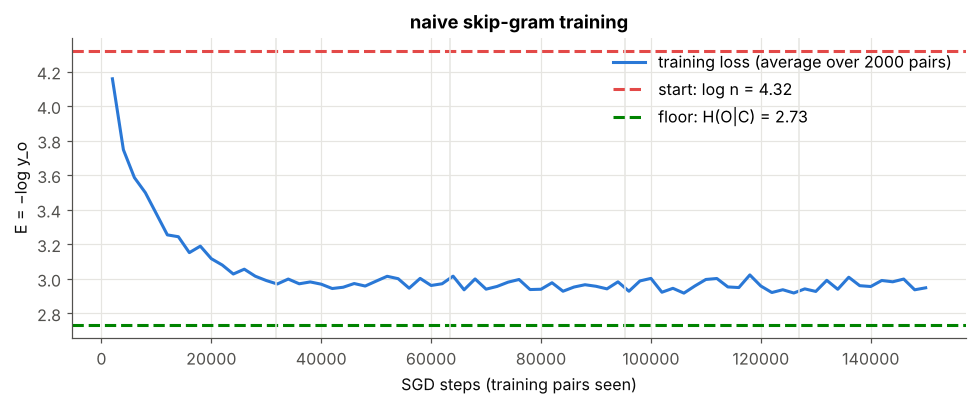

In [14]:
fig, ax = plt.subplots(figsize=(9, 3.8))
steps_axis = np.arange(1, len(curve) + 1) * 2000
ax.plot(steps_axis, curve, color=C["blue"], lw=2, label="training loss (average over 2000 pairs)")
ax.axhline(np.log(n), color=C["red"], ls="--", label=f"start: log n = {np.log(n):.2f}")
ax.axhline(H_floor, color=C["green"], ls="--", label=f"floor: H(O|C) = {H_floor:.2f}")
for ep in range(1, epochs):
    ax.axvline(ep * N, color=C["grid"], lw=1)
ax.set_xlabel("SGD steps (training pairs seen)"); ax.set_ylabel("E = −log y_o")
ax.set_title("naive skip-gram training"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

---
## 6 · What did the network learn to predict? 🔮

The network's own task is to predict neighbours. Compare its top predictions with the true frequencies $P(o\mid c)$ counted from the corpus:

In [15]:
for w in ["king", "girl", "mango", "bank"]:
    true_top = np.argsort(-P_true[index[w]])[:6]
    print(f"{w:>6}  model: {model.predict_context(w)}")
    print(f"{'':>6}  data : {[(vocab[i], round(float(P_true[index[w], i]), 3)) for i in true_top]}\n")

  king  model: [('the', 0.294), ('works', 0.112), ('kingdom', 0.08), ('beard', 0.072), ('his', 0.069), ('throne', 0.053)]
        data : [('the', 0.25), ('his', 0.074), ('works', 0.074), ('beard', 0.066), ('palace', 0.066), ('kingdom', 0.066)]

  girl  model: [('the', 0.405), ('cottage', 0.102), ('farm', 0.084), ('market', 0.07), ('hers', 0.046), ('village', 0.038)]
        data : [('the', 0.25), ('cottage', 0.077), ('dress', 0.074), ('hers', 0.067), ('plays', 0.067), ('toys', 0.064)]

 mango  model: [('i', 0.184), ('eat', 0.162), ('like', 0.138), ('tree', 0.125), ('juicy', 0.112), ('sweet', 0.081)]
        data : [('i', 0.2), ('like', 0.2), ('the', 0.2), ('ripe', 0.113), ('sweet', 0.082), ('eat', 0.072)]

  bank  model: [('the', 0.141), ('like', 0.102), ('rupees', 0.073), ('pay', 0.072), ('loan', 0.068), ('money', 0.063)]
        data : [('the', 0.285), ('like', 0.146), ('loan', 0.052), ('cash', 0.047), ('rupees', 0.045), ('interest', 0.045)]



**The two distributions for *king*** – the model's $y$ and the counted $P(o\mid\text{king})$:

In [16]:
_, y_king = model.forward(index["king"])
p_king = P_true[index["king"]]
print(f"largest gap |y − P| = {np.abs(y_king - p_king).max():.3f}  (word: {vocab[np.argmax(np.abs(y_king - p_king))]})")

largest gap |y − P| = 0.044  (word: the)


📊 **Plot:** model prediction $y$ vs true $P(o\mid c)$ for *king*, over the whole vocabulary. Points on the diagonal are perfect.

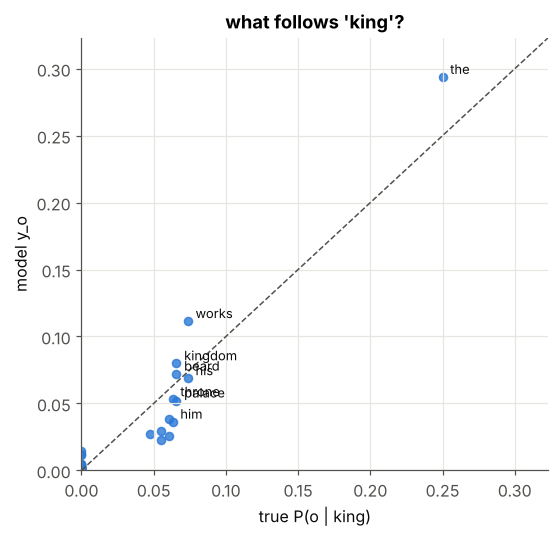

In [17]:
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(p_king, y_king, color=C["blue"], s=28, alpha=0.8)
for i in np.argsort(-p_king)[:8]:
    ax.annotate(vocab[i], (p_king[i], y_king[i]), textcoords="offset points", xytext=(5, 2), fontsize=8.5, color=C["ink"])
lim = max(p_king.max(), y_king.max()) * 1.1
ax.plot([0, lim], [0, lim], color=C["muted"], ls="--", lw=1)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel("true P(o | king)"); ax.set_ylabel("model y_o"); ax.set_title("what follows 'king'?")
plt.tight_layout(); plt.show()

---
## 7 · *"Where are my vectors?"* – the columns of $V$ 🗺️

The prediction task was only a pretext. The prize is $V$: words used in similar contexts got similar columns, because they were pushed by the same $u_o$'s (notebook 05, section 5).

### 7.1 · Nearest neighbours
Cosine similarity between unit-length columns:

In [18]:
W = model.vectors()                       # d × n, unit columns

def neighbours(word, k=5):
    sims = W.T @ W[:, index[word]]
    best = [i for i in np.argsort(-sims) if i != index[word]][:k]
    return [(vocab[i], round(float(sims[i]), 2)) for i in best]

for w in ["king", "girl", "mango", "tea", "loan", "river", "bank", "he"]:
    print(f"{w:>6} → {neighbours(w)}")

  king → [('queen', 0.73), ('prince', 0.7), ('man', 0.62), ('she', 0.53), ('princess', 0.53)]
  girl → [('boy', 0.71), ('woman', 0.7), ('princess', 0.64), ('small', 0.59), ('him', 0.57)]
 mango → [('apple', 0.99), ('banana', 0.99), ('grape', 0.97), ('sweet', 0.77), ('juicy', 0.76)]
   tea → [('milk', 0.99), ('coffee', 0.99), ('water', 0.98), ('cup', 0.78), ('hot', 0.78)]
  loan → [('money', 0.99), ('interest', 0.98), ('account', 0.98), ('save', 0.81), ('rupees', 0.77)]
 river → [('fish', 0.99), ('stream', 0.98), ('boat', 0.98), ('shore', 0.81), ('swim', 0.8)]
  bank → [('flow', 0.74), ('save', 0.73), ('cash', 0.73), ('pay', 0.72), ('shore', 0.72)]
    he → [('him', 0.98), ('his', 0.98), ('beard', 0.97), ('dress', 0.62), ('her', 0.61)]


*bank* sits between the money words and the river words – one vector has to serve both meanings. (More on this in notebook 09.)

📊 **Plot:** cosine similarity between a selection of words. Blocks along the diagonal = groups the model discovered on its own.

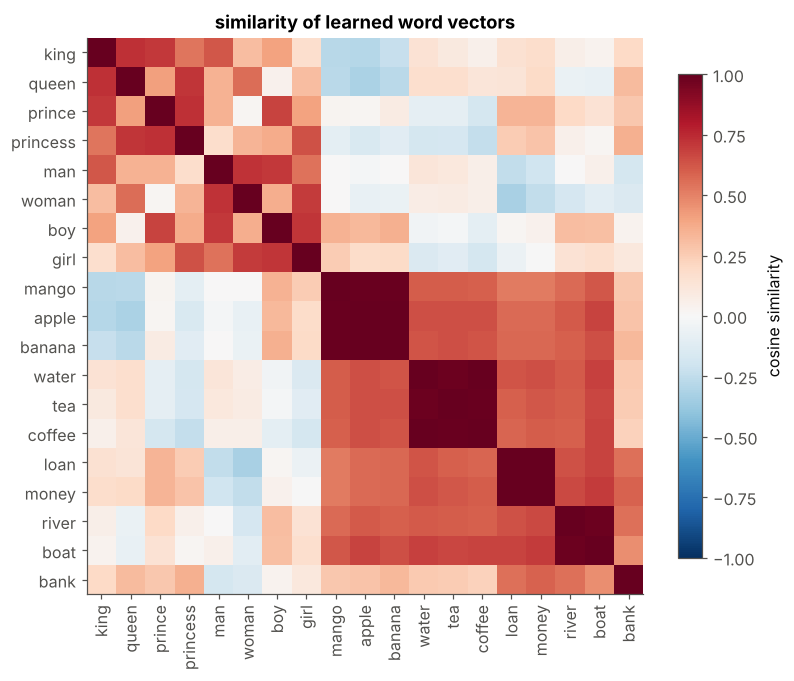

In [19]:
show = ["king", "queen", "prince", "princess", "man", "woman", "boy", "girl",
        "mango", "apple", "banana", "water", "tea", "coffee", "loan", "money", "river", "boat", "bank"]
ids = [index[w] for w in show]
S = W[:, ids].T @ W[:, ids]
fig, ax = plt.subplots(figsize=(7.4, 6.4))
im = ax.imshow(S, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(show)), show, rotation=90); ax.set_yticks(range(len(show)), show); ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8, label="cosine similarity")
ax.set_title("similarity of learned word vectors")
plt.tight_layout(); plt.show()

### 7.2 · A 2-D map
$d=10$ is too many dimensions to draw, so we project onto the 2 directions of largest variance (PCA – the same idea as the SVD in notebook 02). We leave out the function words *the, i, like, …*.

In [20]:
# ---------- plotting helper (visualisation only) ----------
CAT_COLOURS = {"royal person": C["violet"], "common person": C["magenta"], "person context": C["muted"],
               "fruit": C["orange"], "drink": C["blue"], "money": C["green"], "river": C["aqua"],
               "thing context": C["yellow"], "function word": C["grid"]}

def pca_2d(X):
    """Rows of X → 2-D coordinates along the two main directions."""
    Xc = X - X.mean(axis=0)
    _, _, Vt = np.linalg.svd(Xc, full_matrices=False)
    return Xc @ Vt[:2].T


def plot_word_map(ax, W, title):
    words = [w for w in vocab if category[w] != "function word"]
    P = pca_2d(W[:, [index[w] for w in words]].T)
    for w, (px, py) in zip(words, P):
        col = CAT_COLOURS[category[w]]
        ax.scatter(px, py, color=col, s=34, zorder=3)
        ax.annotate(w, (px, py), textcoords="offset points", xytext=(4, 3), fontsize=7.5, color=col if col != C["muted"] else C["ink"])
    for cat, col in CAT_COLOURS.items():
        if cat != "function word":
            ax.scatter([], [], color=col, label=cat)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])

📊 **Plot:** the learned word vectors, coloured by the hidden category we used to generate the corpus. The model never saw these colours.

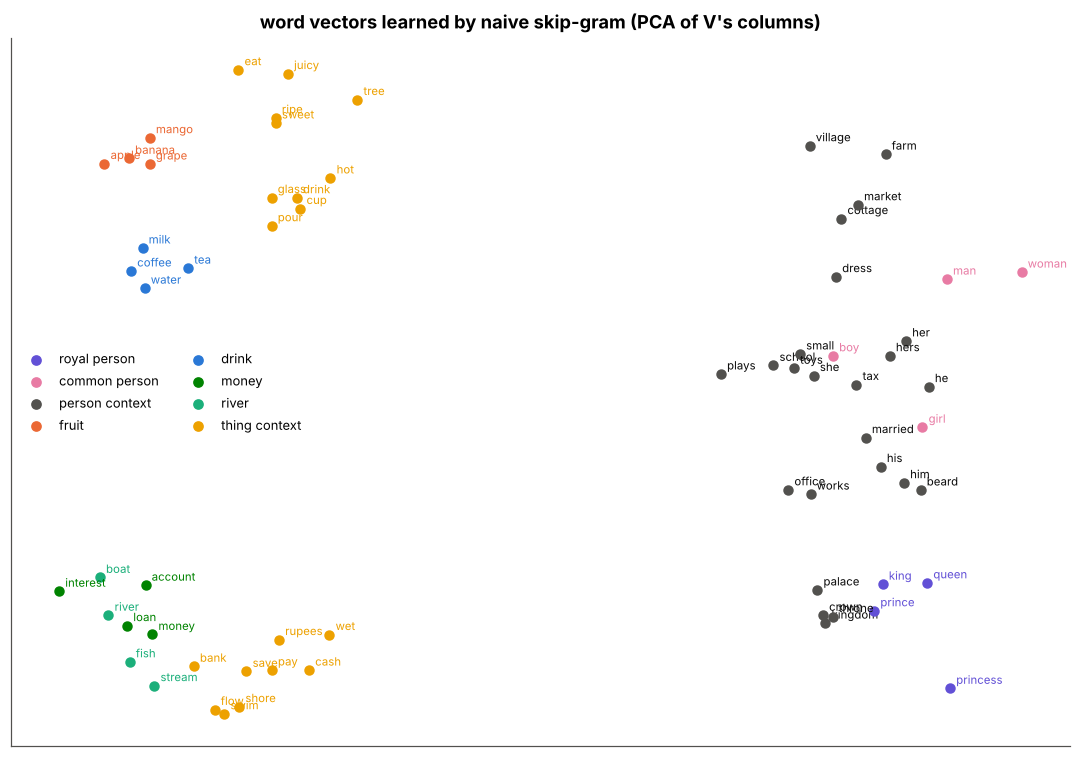

In [21]:
fig, ax = plt.subplots(figsize=(10, 7))
plot_word_map(ax, W, "word vectors learned by naive skip-gram (PCA of V's columns)")
ax.legend(loc="best", fontsize=8.5, ncol=2)
plt.tight_layout(); plt.show()

### 7.3 · Analogies
*king − man + woman* should be closest to *queen*: the vector difference *man → woman* encodes "female", and adding it to *king* should land on the female royal. We search the whole vocabulary, excluding the three input words.

In [22]:
def analogy(a, b, c, W=None, k=3):
    """a − b + c → the k closest words (cosine)."""
    W = model.vectors() if W is None else W
    q = W[:, index[a]] - W[:, index[b]] + W[:, index[c]]
    sims = W.T @ (q / np.linalg.norm(q))
    for w in (a, b, c):
        sims[index[w]] = -np.inf
    return [vocab[i] for i in np.argsort(-sims)[:k]]

tests = [("king", "man", "woman", "queen"), ("prince", "boy", "girl", "princess"), ("queen", "woman", "man", "king"),
         ("man", "boy", "princess", "queen"), ("girl", "woman", "king", "prince")]
for a, b, c, want in tests:
    got = analogy(a, b, c)
    print(f"{a} − {b} + {c} = {got}   {'✅' if got[0] == want else '❌'} (expected {want})")

king − man + woman = ['queen', 'princess', 'crown']   ✅ (expected queen)
prince − boy + girl = ['princess', 'queen', 'him']   ✅ (expected princess)
queen − woman + man = ['king', 'prince', 'she']   ✅ (expected king)
man − boy + princess = ['queen', 'king', 'woman']   ✅ (expected queen)
girl − woman + king = ['prince', 'princess', 'rupees']   ✅ (expected prince)


---
## 8 · The price: how much work is one step? ⏱️

`sgd_step` changed $nd+d$ numbers every time. For our toy model:

In [23]:
print(f"per step: n·d + d = {n} × {d} + {d} = {n * d + d} values")
print(f"one epoch: {N:,} steps → {N * (n * d + d):,} values,  {np.mean(epoch_times):.2f} s")

per step: n·d + d = 75 × 10 + 10 = 760 values
one epoch: 31,734 steps → 24,117,840 values,  0.67 s


With the notes' realistic sizes $d=300$, $n=10^5$, one step updates $3\times10^7$ values, and a real corpus has billions of pairs:

In [24]:
d_real, n_real, N_real = 300, 100_000, 1_000_000_000
per_step = n_real * d_real + d_real
print(f"per step : {per_step:.1e} values")
print(f"1 epoch  : {per_step * N_real:.1e} values  (N = {N_real:.0e} pairs)")

per step : 3.0e+07 values
1 epoch  : 3.0e+16 values  (N = 1e+09 pairs)


### 8.1 · Measuring it
Time one `sgd_step` for growing vocabularies with $d=100$. If the cost is $O(nd)$ the time should grow in a straight line with $n$.

In [25]:
def time_step(n_vocab, d=100, repeats=30):
    m = SkipGramSoftmax(n_vocab, d, seed=0)
    r = np.random.default_rng(0)
    cs, os_ = r.integers(0, n_vocab, repeats), r.integers(0, n_vocab, repeats)
    t0 = time.perf_counter()
    for c, o in zip(cs, os_):
        m.sgd_step(c, o, 0.01)
    return (time.perf_counter() - t0) / repeats

vocab_sizes = [100, 1_000, 5_000, 10_000, 25_000, 50_000, 100_000]
step_times = [time_step(nv) for nv in vocab_sizes]
for nv, t in zip(vocab_sizes, step_times):
    print(f"n = {nv:>7,}:  {t * 1e3:7.3f} ms per step")

n =     100:    0.050 ms per step
n =   1,000:    0.446 ms per step
n =   5,000:    2.381 ms per step
n =  10,000:    6.032 ms per step
n =  25,000:   15.829 ms per step
n =  50,000:   35.099 ms per step
n = 100,000:   87.427 ms per step


📊 **Plot:** time per step grows linearly with $n$. At $n=10^5$, a single step costs tens of milliseconds – multiplied by $10^9$ pairs that is weeks of computation for one epoch.

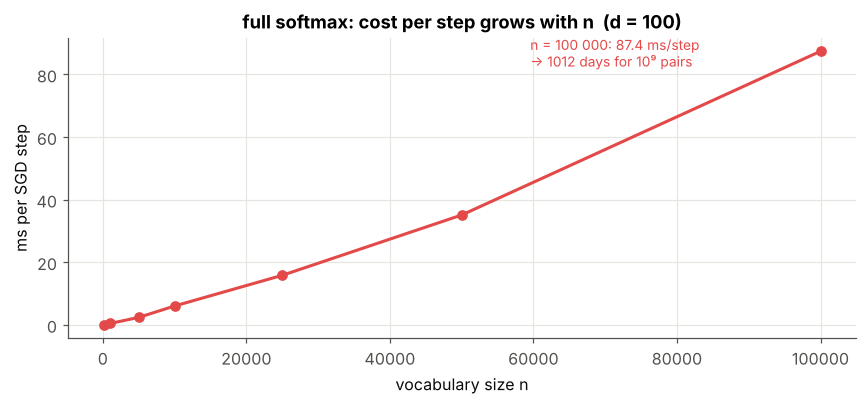

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(vocab_sizes, np.array(step_times) * 1e3, "o-", color=C["red"], lw=2)
ax.set_xlabel("vocabulary size n"); ax.set_ylabel("ms per SGD step"); ax.set_title("full softmax: cost per step grows with n  (d = 100)")
days = step_times[-1] * N_real / 86400
ax.annotate(f"n = 100 000: {step_times[-1] * 1e3:.1f} ms/step\n→ {days:.0f} days for 10⁹ pairs", (vocab_sizes[-1], step_times[-1] * 1e3),
            textcoords="offset points", xytext=(-190, -10), fontsize=9, color=C["red"])
plt.tight_layout(); plt.show()

Where does the cost come from? Two places, both of size $n$:
* the **softmax denominator** $\sum_{m=1}^ne^{z_m}$ needs all $n$ scores;
* the **update** touches all $n$ rows of $U$, because every word with $y_k>0$ gets pushed away.

Notebook 07 (negative sampling) removes both by updating only $k+1\approx10$ rows. Notebook 08 (hierarchical softmax) replaces the $n$-way choice by $\approx\log_2n$ binary choices.

---
## 9 · Summary 📌

| | |
|---|---|
| training | SGD over all skip-gram pairs, update from notebook 05 |
| loss | from $\log n$ down towards the floor $H(O\mid C)$ |
| result | columns of $V$: similar words close, analogies work |
| cost per step | $nd+d$ values – $3\times10^7$ for $d=300$, $n=10^5$ |
| problem | time grows linearly with the vocabulary |

### ✍️ Try it yourself
1. Train with $d=2$ and plot $V$ directly (no PCA). Which groups survive?
2. Increase $\eta$ to 0.5. What happens to the loss curve?
3. Use window $m=1$ instead of 3. Do the analogies still work? Why might a small window hurt here?
4. Average $V$ and $U^\top$ (the input and output vectors) and redo the analogies. Better or worse?

**Next →** `07 - Negative Sampling`: the same model, but each step updates only a handful of rows.